In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pm4py
from pathlib import Path
#XES = DATA / "BPIC17.xes.gz"

log = pm4py.read_xes('data/BPIC17.xes.gz')   # returns a DataFrame in recent versions



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing


/Users/Louis/bpic17-assignment/.venv/lib/python3.11/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(
/Users/Louis/bpic17-assignment/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 31509/31509 [00:19<00:00, 1596.53it/s]


In [2]:
#print(log)
df = log #.sort_values(["case:concept:name", "time:timestamp"])
print(df.shape)
print(df["EventOrigin"].value_counts())
#print(df["case:concept:name"].value_counts())
print(df["lifecycle:transition"].value_counts())

print(df.describe())
print(df)
#print(df['Action org:resource'])

print(f"Amount of Cases: {df['case:concept:name'].nunique()}")
print(f"Amount of Cases: {df['concept:name'].nunique()}")

#df = df.sample(frac=0.01)
#print(df)

wf = df[df["EventOrigin"] == "Workflow"]

# all lifecycle values for workflow events, with counts
print(wf["lifecycle:transition"].value_counts(dropna=False))


print(df["Accepted"].value_counts())

# per activity: which lifecycle values does each W_ activity have?
print(pd.crosstab(wf["concept:name"], wf["lifecycle:transition"]))

(1202267, 19)
EventOrigin
Workflow       768823
Application    239595
Offer          193849
Name: count, dtype: int64
lifecycle:transition
complete     475306
suspend      215402
schedule     149104
start        128227
resume       127160
ate_abort     85224
withdraw      21844
Name: count, dtype: int64
       case:RequestedAmount  FirstWithdrawalAmount  NumberOfTerms  \
count          1.202267e+06           42995.000000   42995.000000   
mean           1.675947e+04            8394.338979      83.041982   
std            1.572320e+04           10852.443358      36.386199   
min            0.000000e+00               0.000000       5.000000   
25%            6.000000e+03               0.000000      56.000000   
50%            1.400000e+04            5000.000000      77.000000   
75%            2.300000e+04           12000.000000     120.000000   
max            4.500000e+05           75000.000000     180.000000   

        MonthlyCost   CreditScore  OfferedAmount  
count  42995.000000  4

In [3]:
cid, act = "case:concept:name", "concept:name"

# 1) A_/O_ lifecycle values (expect only 'complete')
ao = df[df["EventOrigin"].isin(["Application", "Offer"])]
print(ao["lifecycle:transition"].value_counts(dropna=False))

# 2) share of events per origin
print(df["EventOrigin"].value_counts(normalize=True).round(3))

# 3) evidence for the report: variants with vs without W_ events
v_all = len(pm4py.get_variants(df))
v_ao = len(pm4py.get_variants(ao))
print("variants with W_:", v_all, "| without W_:", v_ao)

# 4) work items per case and suspend/resume cycles per case (workload of W_)
wf = df[df["EventOrigin"] == "Workflow"]
per_case = wf.groupby(cid).size()
print("W_ events per case:\n", per_case.describe().round(1))
print("share of cases with at least one W_ event:", round(per_case.size / df[cid].nunique(), 3))

lifecycle:transition
complete    433444
Name: count, dtype: int64
EventOrigin
Workflow       0.639
Application    0.199
Offer          0.161
Name: proportion, dtype: float64
variants with W_: 15930 | without W_: 2630
W_ events per case:
 count    31509.0
mean        24.4
std         13.7
min          3.0
25%         14.0
50%         21.0
75%         31.0
max        151.0
dtype: float64
share of cases with at least one W_ event: 1.0


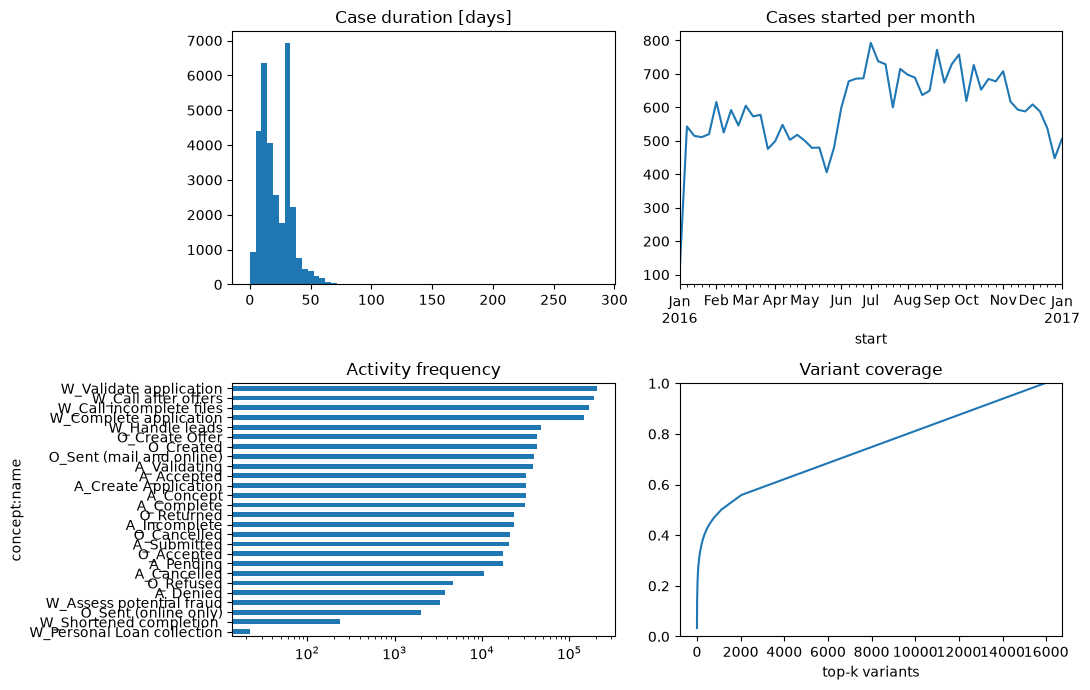

cases: 31509 | variants: 15930 | top-10 coverage: 0.153
      dur_days  length
mean     21.90   38.16
std      13.17   16.72


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pm4py
cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"
g = df.groupby(cid)[ts]
cases = pd.DataFrame({"start": g.min(), "dur_days": (g.max() - g.min()).dt.total_seconds() / 86400,
                      "length": df.groupby(cid).size()})
variants = pm4py.get_variants(df)
counts = np.sort(np.array(list(variants.values())))[::-1]

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].hist(cases["dur_days"], bins=60); ax[0, 0].set(title="Case duration [days]")
cases.groupby(cases["start"].dt.tz_localize(None).dt.to_period("W")).size().plot(ax=ax[0, 1], title="Cases started per month")
df[act].value_counts().sort_values().plot.barh(ax=ax[1, 0], logx=True, title="Activity frequency")
ax[1, 1].plot(np.cumsum(counts) / counts.sum()); ax[1, 1].set(title="Variant coverage", xlabel="top-k variants", ylim=(0, 1))
plt.tight_layout(); plt.show()

print("cases:", len(cases), "| variants:", len(variants),
      "| top-10 coverage:", round(counts[:10].sum() / counts.sum(), 3))
print(cases[["dur_days", "length"]].agg(["mean", "std"]).round(2))

In [5]:
import pandas as pd, pm4py

cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"
funnel = []
def log_step(name, x):
    funnel.append({"step": name, "cases": x[cid].nunique(), "events": len(x),
                   "variants": len(pm4py.get_variants(x))})

# 1) nur A_/O_ Events, immer von log (Rohdaten) aus starten
df = (log[log["EventOrigin"].isin(["Application", "Offer"])]
      .sort_values([cid, ts], kind="stable").reset_index(drop=True))
log_step("1 nur A_/O_", df)

# 2) nur Cases mit Endzustand
ids_end = df.loc[df[act].isin(["A_Pending", "A_Denied", "A_Cancelled"]), cid].unique()
df = df[df[cid].isin(ids_end)].reset_index(drop=True)
log_step("2 nur Cases mit Endzustand", df)

# 3) Endzustand zusammenfassen: zugehoerige O_-Events (max. 2 min vom Endzustand) loeschen, Endzustand umbenennen
END = {"A_Pending": ("Pending", "O_Accepted"),
       "A_Denied": ("Denied", "O_Refused"),
       "A_Cancelled": ("Cancelled", "O_Cancelled")}
for a_name, (new, o_name) in END.items():
    t_end = df.loc[df[act] == a_name].groupby(cid)[ts].max()        # Zeitpunkt des Endzustands pro Case
    t = df[cid].map(t_end)
    drop = (df[act] == o_name) & t.notna() & ((df[ts] - t).abs() < pd.Timedelta("2min"))
    df.loc[df[act] == a_name, act] = new
    df = df[~drop].reset_index(drop=True)
log_step("3 Endzustand zusammengefasst", df)

# 4) direkt aufeinanderfolgende gleiche Aktivitaeten zusammenfassen
df = df[df[act] != df.groupby(cid)[act].shift()].reset_index(drop=True)
log_step("4 Wiederholungen zusammengefasst", df)
print(pd.DataFrame(funnel).to_string(index=False))

# O_Cancelled nach Pending loeschen (automatische Folge der Annahme)
after_pending = df[act].eq("Pending").groupby(df[cid]).cummax() & df[act].eq("O_Cancelled")
df = df[~after_pending].reset_index(drop=True)

# Kontrolle: letzte Aktivitaet pro Case sollte Pending/Denied/Cancelled sein, O_-Events danach sind Reste
print(df.groupby(cid)[act].last().value_counts())

# 5) Stichprobe ganzer Cases (feste Seed) aus dem bereinigten df
ids = pd.Series(df[cid].unique()).sample(1500, random_state=42)
df_s = df[df[cid].isin(ids)]
print("sample:", df_s[cid].nunique(), "cases,", len(df_s), "events")
df_s = df

                            step  cases  events  variants
                     1 nur A_/O_  31509  433444      2630
      2 nur Cases mit Endzustand  31411  432197      2588
    3 Endzustand zusammengefasst  31411  397115      2567
4 Wiederholungen zusammengefasst  31411  392202      2451
concept:name
Pending      17228
Cancelled    10431
Denied        3752
Name: count, dtype: int64
sample: 1500 cases, 18711 events


Inductive nt=0.0       places= 40 transitions= 53 arcs=118
Inductive nt=0.2       places= 22 transitions= 28 arcs= 62
Inductive nt=0.5       places= 18 transitions= 23 arcs= 50
Inductive nt=0.9       places= 18 transitions= 23 arcs= 50
Heuristics dep=0.2     places= 23 transitions= 40 arcs= 90
Heuristics dep=0.5     places= 24 transitions= 42 arcs= 94
Heuristics dep=0.9     places= 24 transitions= 45 arcs=100
Alpha                  places= 29 transitions= 16 arcs= 95


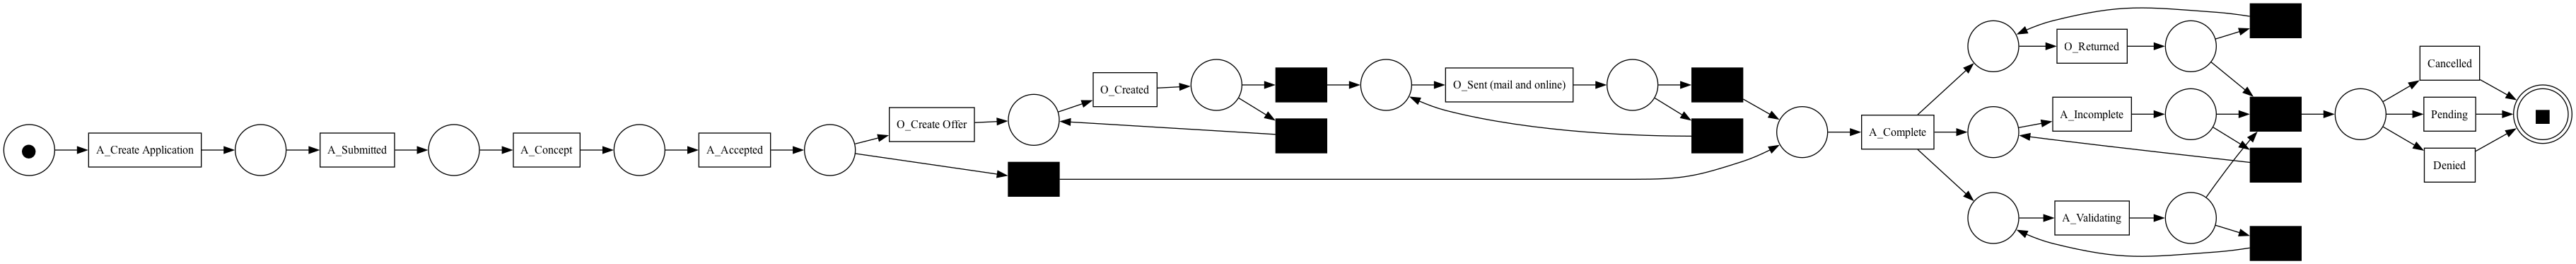

In [6]:
import pm4py

models = {}

# Inductive miner: noise_threshold filters infrequent behavior (0 = none, higher = more filtering)
for nt in [0.0, 0.2, 0.5, 0.9]:
    models[f"Inductive nt={nt}"] = pm4py.discover_petri_net_inductive(df_s, noise_threshold=nt)

# Heuristics miner: dependency_threshold keeps only strong dependencies (higher = simpler model)
for dep in [0.2, 0.5, 0.9]:
    models[f"Heuristics dep={dep}"] = pm4py.discover_petri_net_heuristics(df_s, dependency_threshold=dep)

# Alpha miner: no parameters, usually weak on real logs, serves as a baseline
models["Alpha"] = pm4py.discover_petri_net_alpha(df_s)

# quick overview of model size and a look at two of them
for name, (net, im, fm) in models.items():
    print(f"{name:22s} places={len(net.places):3d} transitions={len(net.transitions):3d} arcs={len(net.arcs):3d}")

pm4py.view_petri_net(*models["Inductive nt=0.5"])

replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1346.01it/s]


Inductive nt=0.0       done in 24s


replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1909.49it/s]

Inductive nt=0.1       done in 12s



replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1925.78it/s]


Inductive nt=0.2       done in 13s


... (6 outputs left out)

replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1575.92it/s]


Heuristics dep=0.5     done in 13s


replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1644.46it/s]


Heuristics dep=0.9     done in 15s
                    cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size    CNC  density  XOR_places   sec
Inductive nt=0.0        1.000    1.000     0.453           0.960            0.650  93.0  1.269    0.028        19.0  24.0
Inductive nt=0.1        0.940    0.994     0.589           0.989            0.667  48.0  1.250    0.054        10.0  12.0
Inductive nt=0.2        0.714    0.978     0.621           0.921            0.676  50.0  1.240    0.050         9.0  13.0
Inductive nt=0.5        0.194    0.903     0.673           0.863            0.695  41.0  1.220    0.060         7.0  13.0
Inductive nt=0.9        0.194    0.903     0.673           0.863            0.695  41.0  1.220    0.060         7.0  11.0
Heuristics dep=0.2      0.002    0.894     0.915           0.956            0.538  63.0  1.429    0.049         9.0  13.0
Heuristics dep=0.5      0.003    0.906     0.915           0.943            0.541  66.0  1.424    0.047        

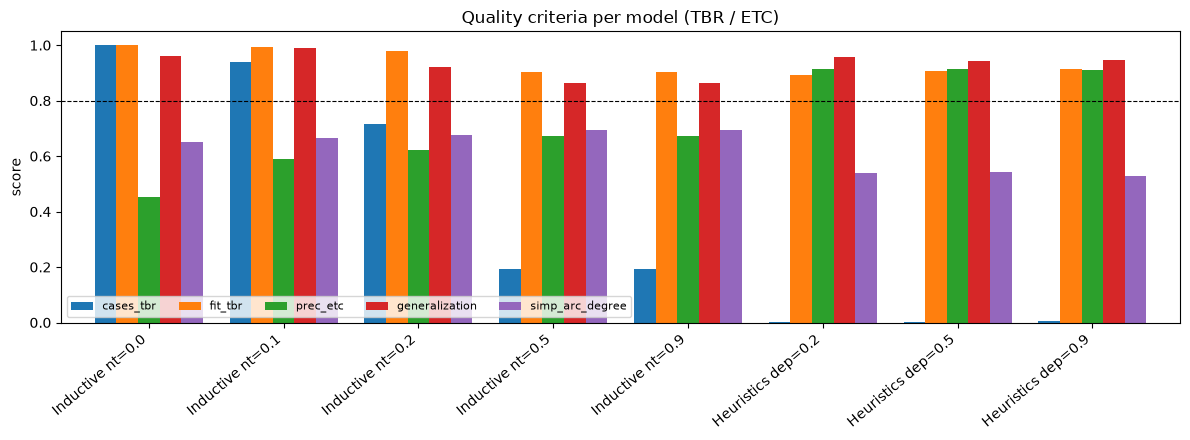

In [7]:
import time, warnings
import pandas as pd, pm4py, matplotlib.pyplot as plt
from pm4py.algo.evaluation.generalization import algorithm as gen_alg
from pm4py.algo.evaluation.simplicity import algorithm as simp_alg
warnings.filterwarnings("ignore")

INCLUDE_ALPHA = False        # Alpha nets are often unsound and slow to evaluate; switch on last

models = {}
for nt in [0.0, 0.1, 0.2, 0.5, 0.9]:
    models[f"Inductive nt={nt}"] = pm4py.discover_petri_net_inductive(df, noise_threshold=nt)
for dep in [0.2, 0.5, 0.9]:
    models[f"Heuristics dep={dep}"] = pm4py.discover_petri_net_heuristics(df, dependency_threshold=dep)
if INCLUDE_ALPHA:
    models["Alpha"] = pm4py.discover_petri_net_alpha(df)

rows = {}
try:
    for name, (net, im, fm) in models.items():
        t0 = time.time()
        try:
            tb = pm4py.fitness_token_based_replay(df, net, im, fm)
            n = len(net.places) + len(net.transitions)
            rows[name] = {"cases_tbr": tb["perc_fit_traces"] / 100, "fit_tbr": tb["log_fitness"],
                          "prec_etc": pm4py.precision_token_based_replay(df, net, im, fm),
                          "generalization": gen_alg.apply(df, net, im, fm),
                          "simp_arc_degree": simp_alg.apply(net), "size": n,
                          "CNC": len(net.arcs) / n,
                          "density": len(net.arcs) / (2 * len(net.places) * len(net.transitions)),
                          "XOR_places": sum(len(p.out_arcs) > 1 for p in net.places),
                          "sec": round(time.time() - t0)}
            print(f"{name:22s} done in {rows[name]['sec']}s", flush=True)
        except Exception as e:
            print(f"{name:22s} FAILED: {type(e).__name__} {e}", flush=True)
except KeyboardInterrupt:
    print("interrupted, showing the models that finished")

res = pd.DataFrame(rows).T
print(res.round(3).to_string())

cols = ["cases_tbr", "fit_tbr", "prec_etc", "generalization", "simp_arc_degree"]
ax = res[cols].astype(float).plot.bar(figsize=(12, 4.5), width=0.8, title="Quality criteria per model (TBR / ETC)")
ax.axhline(0.8, color="k", ls="--", lw=0.8)
ax.set(ylim=(0, 1.05), ylabel="score")
plt.xticks(rotation=40, ha="right"); plt.legend(loc="lower left", ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

aligning log, completed variants :: 100%|██████████| 2438/2438 [00:16<00:00, 145.37it/s]
computing precision with alignments, completed variants :: 100%|██████████| 7053/7053 [00:06<00:00, 1077.07it/s]


FINAL: top-13 variants, nt=0       done in 43s


replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1277.15it/s]


Inductive nt=0.0                   done in 26s


aligning log, completed variants :: 100%|██████████| 2438/2438 [00:28<00:00, 84.30it/s] 
computing precision with alignments, completed variants :: 100%|██████████| 7053/7053 [00:06<00:00, 1010.40it/s]


Inductive nt=0.2                   done in 56s


replaying log with TBR, completed traces :: 100%|██████████| 2438/2438 [00:01<00:00, 1562.15it/s]


Heuristics dep=0.5                 done in 13s
                              cases_tbr  fit_tbr  prec_etc  generalization  simp_arc_degree  size    CNC  density  XOR_places  cases_align  fit_align  prec_align   sec
FINAL: top-13 variants, nt=0      0.882    0.990     0.744           0.992            0.724  42.0  1.190    0.057         7.0        0.841      0.980       0.750  43.0
Inductive nt=0.0                  1.000    1.000     0.453           0.960            0.650  93.0  1.269    0.028        19.0          NaN        NaN         NaN  26.0
Inductive nt=0.2                  0.714    0.978     0.621           0.921            0.676  50.0  1.240    0.050         9.0        0.713      0.962       0.624  56.0
Heuristics dep=0.5                0.002    0.906     0.912           0.957            0.541  66.0  1.424    0.047         9.0          NaN        NaN         NaN  13.0


aligning log, completed variants :: 100%|██████████| 1511/1511 [00:09<00:00, 163.53it/s]
computing precision with alignments, completed variants :: 100%|██████████| 4314/4314 [00:04<00:00, 973.95it/s] 


holdout (train half -> test half)  done in 24s
HOLDOUT: {'cases_tbr': 0.8813192410543741, 'fit_tbr': 0.9896234001543917, 'prec_etc': 0.7402084131065041, 'generalization': 0.989227083331042, 'simp_arc_degree': 0.7241379310344828, 'size': 42, 'CNC': 1.1904761904761905, 'density': 0.057208237986270026, 'XOR_places': 7, 'cases_align': 0.8408888322933911, 'fit_align': 0.9800036995637257, 'prec_align': 0.7472545150865638, 'sec': 24}


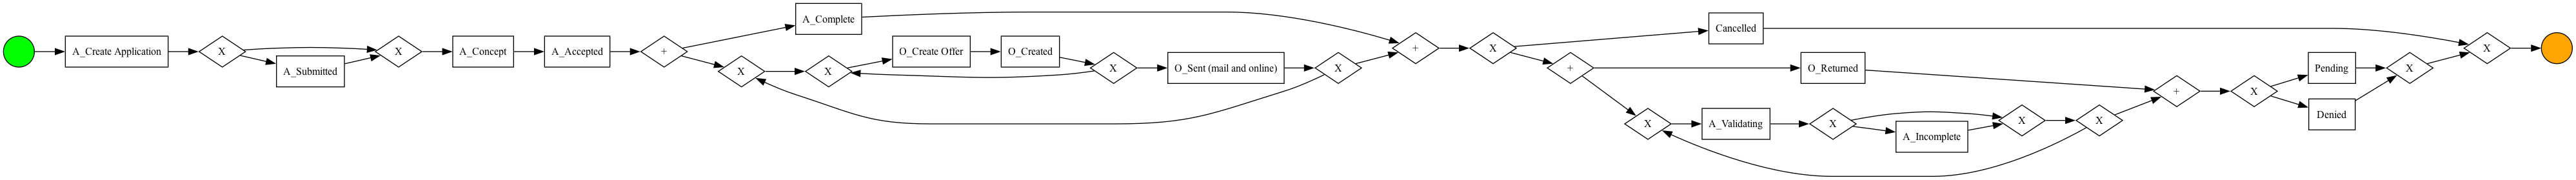

In [8]:
import time, warnings
import pandas as pd, pm4py
from sklearn.model_selection import train_test_split
from pm4py.algo.evaluation.generalization import algorithm as gen_alg
from pm4py.algo.evaluation.simplicity import algorithm as simp_alg
warnings.filterwarnings("ignore")
cid = "case:concept:name"
# guard: df must be the cleaned log (A_/O_ only, 387,766 events); update the number if you change the cleaning
assert df["EventOrigin"].isin(["Application", "Offer"]).all() and len(df) == 387766, "df is not the cleaned log"
def evaluate(name, net, im, fm, data, align):
    t0 = time.time()
    tb = pm4py.fitness_token_based_replay(data, net, im, fm)
    n = len(net.places) + len(net.transitions)
    r = {"cases_tbr": tb["perc_fit_traces"] / 100, "fit_tbr": tb["log_fitness"],
         "prec_etc": pm4py.precision_token_based_replay(data, net, im, fm),
         "generalization": gen_alg.apply(data, net, im, fm),
         "simp_arc_degree": simp_alg.apply(net), "size": n,
         "CNC": len(net.arcs) / n,
         "density": len(net.arcs) / (2 * len(net.places) * len(net.transitions)),
         "XOR_places": sum(len(p.out_arcs) > 1 for p in net.places)}
    if align:
        a = pm4py.fitness_alignments(data, net, im, fm)
        r.update(cases_align=a["percFitTraces"] / 100, fit_align=a["log_fitness"],
                 prec_align=pm4py.precision_alignments(data, net, im, fm))
    r["sec"] = round(time.time() - t0)
    print(f"{name:34s} done in {r['sec']}s", flush=True)
    return r

# 1) final model + comparison models, all evaluated on the whole cleaned log
K = 13
tree = pm4py.discover_process_tree_inductive(pm4py.filter_variants_top_k(df, K), noise_threshold=0.0)
final_net = pm4py.convert_to_petri_net(tree)
models = {
    f"FINAL: top-{K} variants, nt=0": (final_net, True),                 # alignments only for the finalists
    "Inductive nt=0.0": (pm4py.discover_petri_net_inductive(df, noise_threshold=0.0), False),
    "Inductive nt=0.2": (pm4py.discover_petri_net_inductive(df, noise_threshold=0.2), True),
    "Heuristics dep=0.5": (pm4py.discover_petri_net_heuristics(df, dependency_threshold=0.5), False),
}
rows = {}
for name, ((net, im, fm), align) in models.items():
    try:
        rows[name] = evaluate(name, net, im, fm, df, align)
    except Exception as e:
        print(f"{name} FAILED: {type(e).__name__} {e}")
res = pd.DataFrame(rows).T
print(res.round(3).to_string())

# 2) holdout: discover on one half of the cases (fixed seed), evaluate on the other half
tr, te = train_test_split(df[cid].unique(), test_size=0.5, random_state=42)
d_tr, d_te = df[df[cid].isin(tr)], df[df[cid].isin(te)]
tree_h = pm4py.discover_process_tree_inductive(pm4py.filter_variants_top_k(d_tr, K), noise_threshold=0.0)
net_h, im_h, fm_h = pm4py.convert_to_petri_net(tree_h)
print("HOLDOUT:", evaluate("holdout (train half -> test half)", net_h, im_h, fm_h, d_te, True))

# 3) export the final model for the report
net, im, fm = final_net
bpmn = pm4py.convert_to_bpmn(tree)
pm4py.write_bpmn(bpmn, "final_model.bpmn")
pm4py.view_bpmn(bpmn)
pm4py.save_vis_bpmn(bpmn, "final_model_bpmn.pdf", rankdir="LR")
pm4py.save_vis_petri_net(net, im, fm, "final_model_petri.pdf")
res.round(3).to_csv("model_comparison_final.csv")

aligning log, completed variants :: 100%|██████████| 1111/1111 [00:06<00:00, 181.36it/s]


 D place     n                                                                                                  branches   acc  baseline   gain
D1  p_16 13163                               {'O_Sent (mail and online)': 0.9, 'O_Create Offer': 0.1, 'A_Complete': 0.0} 0.895     0.895  0.000
D2  p_20  6869                                                                           {'Pending': 0.8, 'Denied': 0.2} 0.801     0.801  0.000
D3   p_3 10000                                                                  {'A_Submitted': 0.65, 'A_Concept': 0.35} 0.837     0.645  0.192
D4   p_7 10000                                             {'A_Validating': 0.68, 'Cancelled': 0.31, 'O_Returned': 0.01} 0.677     0.679 -0.002
D5  p_13 11788 {'A_Validating': 0.58, 'Cancelled': 0.27, 'A_Complete': 0.12, 'O_Create Offer': 0.03, 'O_Returned': 0.01} 0.568     0.576 -0.009
D6  p_27 12103                               {'A_Incomplete': 0.58, 'O_Returned': 0.19, 'Pending': 0.19, 'Denied': 0.03} 0.602     0.585

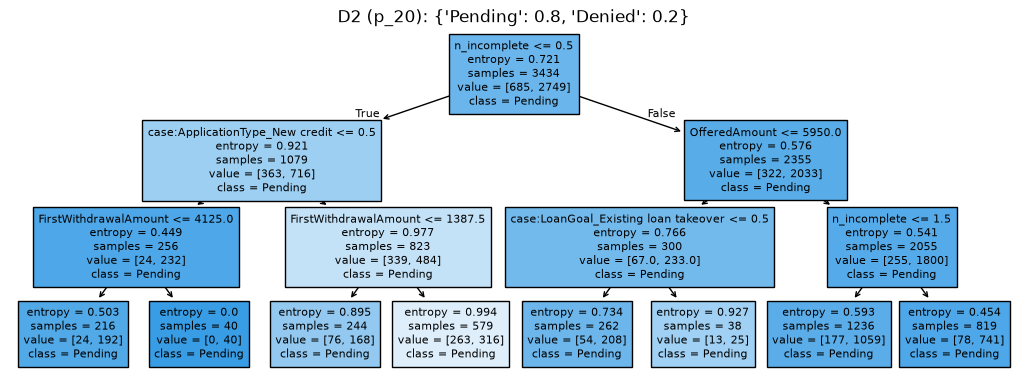

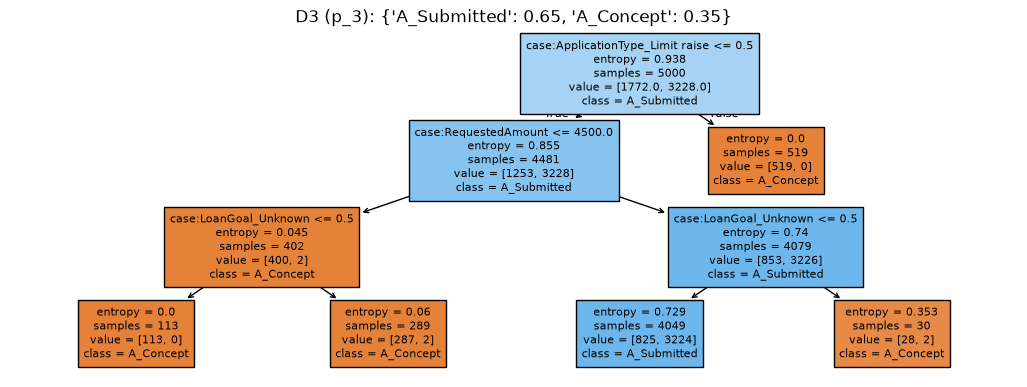

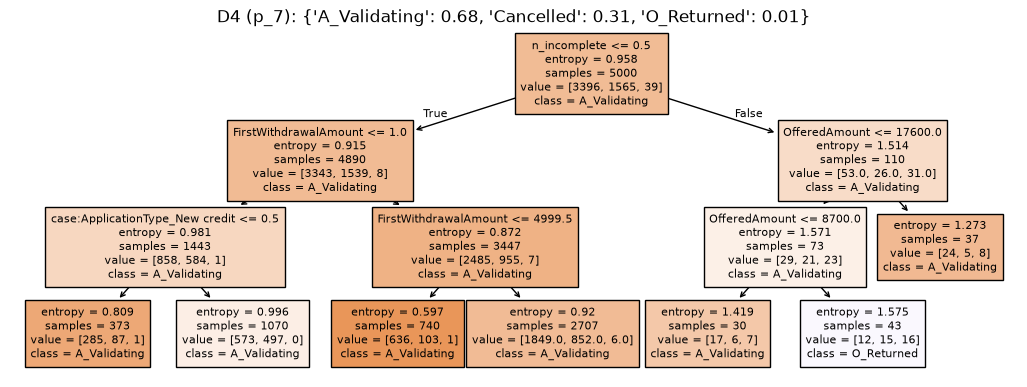

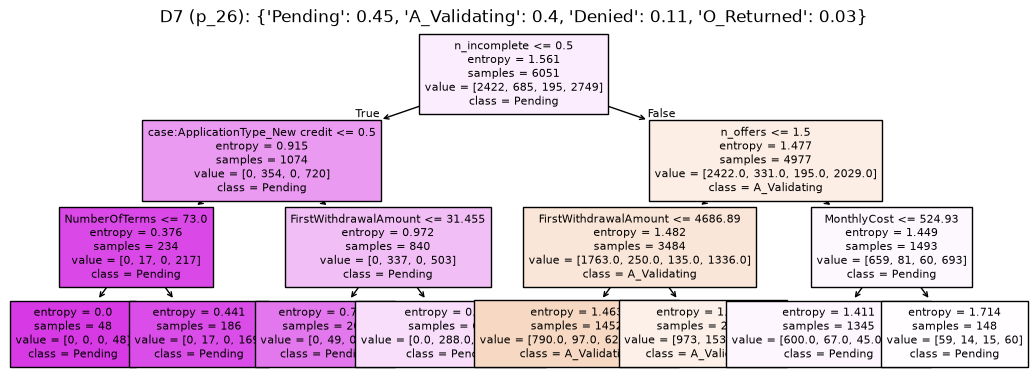

In [10]:
import numpy as np, pandas as pd, pm4py, matplotlib.pyplot as plt
from pm4py.algo.decision_mining import algorithm as dm
from pm4py.algo.conformance.alignments.petri_net import algorithm as al_alg
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

SEED, N_CASES, K = 42, 10000, 13
cid, act, ts = "case:concept:name", "concept:name", "time:timestamp"
FEATS = [a for a in ["case:LoanGoal", "case:ApplicationType", "case:RequestedAmount", "OfferedAmount",
                     "MonthlyCost", "NumberOfTerms", "FirstWithdrawalAmount"] if a in df.columns]
FEATS += ["n_offers", "n_incomplete"]

# final model
tree = pm4py.discover_process_tree_inductive(pm4py.filter_variants_top_k(df, K), noise_threshold=0.0)
net, im, fm = pm4py.convert_to_petri_net(tree)
points = dm.get_decision_points(net)                      # places with more than 1 outgoing arc = the XORs
names = {p: f"D{i}" for i, p in enumerate(points, 1)}
tname = {t.name: t for t in net.transitions}

# sample of whole cases, features known before each event
ids = pd.Series(df[cid].unique()).sample(min(N_CASES, df[cid].nunique()), random_state=SEED)
d = df[df[cid].isin(ids)].sort_values([cid, ts], kind="stable").reset_index(drop=True)
d["n_offers"] = d[act].eq("O_Create Offer").groupby(d[cid]).cumsum()
d["n_incomplete"] = d[act].eq("A_Incomplete").groupby(d[cid]).cumsum()
d[FEATS] = d.groupby(cid)[FEATS].ffill()                  # offer attributes carry forward
case_ids = list(dict.fromkeys(d[cid]))
first = d.index.to_series().groupby(d[cid]).min()         # row of each case's first event

# align every case, record one observation per decision place
als = al_alg.apply(d, net, im, fm, parameters={"ret_tuple_as_trans_desc": True})
assert len(als) == len(case_ids)

obs = {p: [] for p in points}                             # place -> [(row in d, chosen branch)]
for c, al in zip(case_ids, als):
    moves = [m for m, _ in al["alignment"]]               # (log_move, model_move)
    labels = [tname[mod].label if mod not in (">>", None) else None for _, mod in moves]
    nxt, branch = "END", [None] * len(moves)
    for i in reversed(range(len(moves))):                 # branch = next visible activity
        nxt = labels[i] or nxt
        branch[i] = nxt
    n = 0                                                 # events seen so far
    for (log_n, mod_n), b in zip(moves, branch):
        if mod_n not in (">>", None):
            for a in tname[mod_n].in_arcs:
                if a.source.name in points:
                    obs[a.source.name].append((first[c] + max(n - 1, 0), b))
        if log_n not in (">>", None):
            n += 1

# one decision tree per XOR (50/50 split like the paper)
rows, models = [], {}
for p, o in obs.items():
    y = pd.Series([b for _, b in o])
    if len(y) < 50 or y.nunique() < 2:
        rows.append({"D": names[p], "place": p, "n": len(y), "note": "too few / one branch"}); continue
    X = pd.get_dummies(d[FEATS].iloc[[i for i, _ in o]].reset_index(drop=True)).fillna(-1)
    strat = y if y.value_counts().min() >= 2 else None
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, random_state=SEED, stratify=strat)
    clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=30,
                                 random_state=SEED).fit(Xtr, ytr)
    acc, base = clf.score(Xte, yte), (yte == ytr.mode()[0]).mean()
    models[p] = (clf, list(X.columns))
    rows.append({"D": names[p], "place": p, "n": len(y),
                 "branches": y.value_counts(normalize=True).round(2).to_dict(),
                 "acc": round(acc, 3), "baseline": round(base, 3), "gain": round(acc - base, 3)})

summary = pd.DataFrame(rows).sort_values("D")
print(summary.to_string(index=False))

# plot D2 (channel), D4 (credit decision) and every decision with gain > 0.05
for _, r in summary.iterrows():
    if r["place"] in models and (r["D"] in ("D2", "D4") or r["gain"] > 0.05):
        clf, cols = models[r["place"]]
        plt.figure(figsize=(13, 4.5))
        plot_tree(clf, feature_names=cols, class_names=list(clf.classes_), filled=True, fontsize=8)
        plt.title(f"{r['D']} ({r['place']}): {r['branches']}"); plt.show()